<a href="https://colab.research.google.com/github/MaanyaGupta/CSET343/blob/main/Lab4_e23cseu0728_cset343.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab Assignment 4: Logistic Regression
**Course:** CSET343 – AI in Healthcare | B.Tech, 4th Year, Semester VII
**Dataset:** Breast Cancer Wisconsin (Diagnostic)

**Objective:** Preprocess data, train and evaluate a logistic regression classifier for binary diagnosis (benign vs malignant), and interpret the results in a medical context.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)

%matplotlib inline
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")

# Task 1: Data Acquisition and Exploration
## 1. Load the dataset

In [ ]:
data = load_breast_cancer(as_frame=True)   # UCI WDBC dataset bundled with scikit-learn
df = data.frame.copy()
# In scikit-learn: target 0 = malignant, 1 = benign
df["diagnosis"] = df["target"].map({0: "M", 1: "B"})
features = list(data.feature_names)

print("Shape:", df.shape, "-> 569 samples, 30 features + target")
df.head()

Shape: (569, 32) -> 569 samples, 30 features + target


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,M


## 2. Summary statistics

In [ ]:
summary = df[features].describe().T
summary["median"] = df[features].median()
summary = summary[["count", "mean", "median", "std", "min", "25%", "75%", "max"]]
summary.round(3)

,count,mean,median,std,min,25%,75%,max
mean radius,569.0,14.127,13.370,3.524,6.981,11.700,15.780,28.110
mean texture,569.0,19.290,18.840,4.301,9.710,16.170,21.800,39.280
mean perimeter,569.0,91.969,86.240,24.299,43.790,75.170,104.100,188.500
mean area,569.0,654.889,551.100,351.914,143.500,420.300,782.700,2501.000
mean smoothness,569.0,0.096,0.096,0.014,0.053,0.086,0.105,0.163
mean compactness,569.0,0.104,0.093,0.053,0.019,0.065,0.130,0.345
mean concavity,569.0,0.089,0.062,0.080,0.000,0.030,0.131,0.427
mean concave points,569.0,0.049,0.034,0.039,0.000,0.020,0.074,0.201
mean symmetry,569.0,0.181,0.179,0.027,0.106,0.162,0.196,0.304
mean fractal dimension,569.0,0.063,0.062,0.007,0.050,0.058,0.066,0.097


## 3. Missing values, duplicates and outliers

In [ ]:
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Q1, Q3 = df[features].quantile(0.25), df[features].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df[features] < (Q1 - 1.5 * IQR)) | (df[features] > (Q3 + 1.5 * IQR))
print("\nOutliers per feature by the 1.5*IQR rule (top 10):")
print(outlier_mask.sum().sort_values(ascending=False).head(10))
print(f"\nRows with at least one outlier: {int(outlier_mask.any(axis=1).sum())} / {len(df)}")

Missing values: 0
Duplicate rows: 0

Outliers per feature by the 1.5*IQR rule (top 10):
area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64

Rows with at least one outlier: 171 / 569


**Handling:** There are no missing values and no duplicate rows, so nothing needs to be imputed or dropped.
Outliers are flagged in 171 of 569 rows, mostly in the *error* and *area* features. These are genuine measurements of large tumours (not data-entry errors), and removing them would discard malignant cases, so they are **retained**. Standardization (Task 2) and the L2 regularization built into `LogisticRegression` reduce the influence of extreme values.

## 4. Visualizations

**Class distribution**

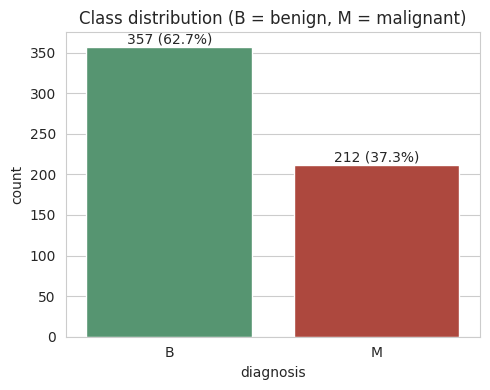

In [ ]:
counts = df["diagnosis"].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="diagnosis", data=df, order=["B", "M"], palette=["#4c9f70", "#c0392b"], ax=ax)
for i, lab in enumerate(["B", "M"]):
    ax.text(i, counts[lab] + 4, f"{counts[lab]} ({counts[lab]/len(df):.1%})", ha="center")
ax.set_title("Class distribution (B = benign, M = malignant)")
plt.tight_layout(); plt.show()

**Histograms of key features by diagnosis**

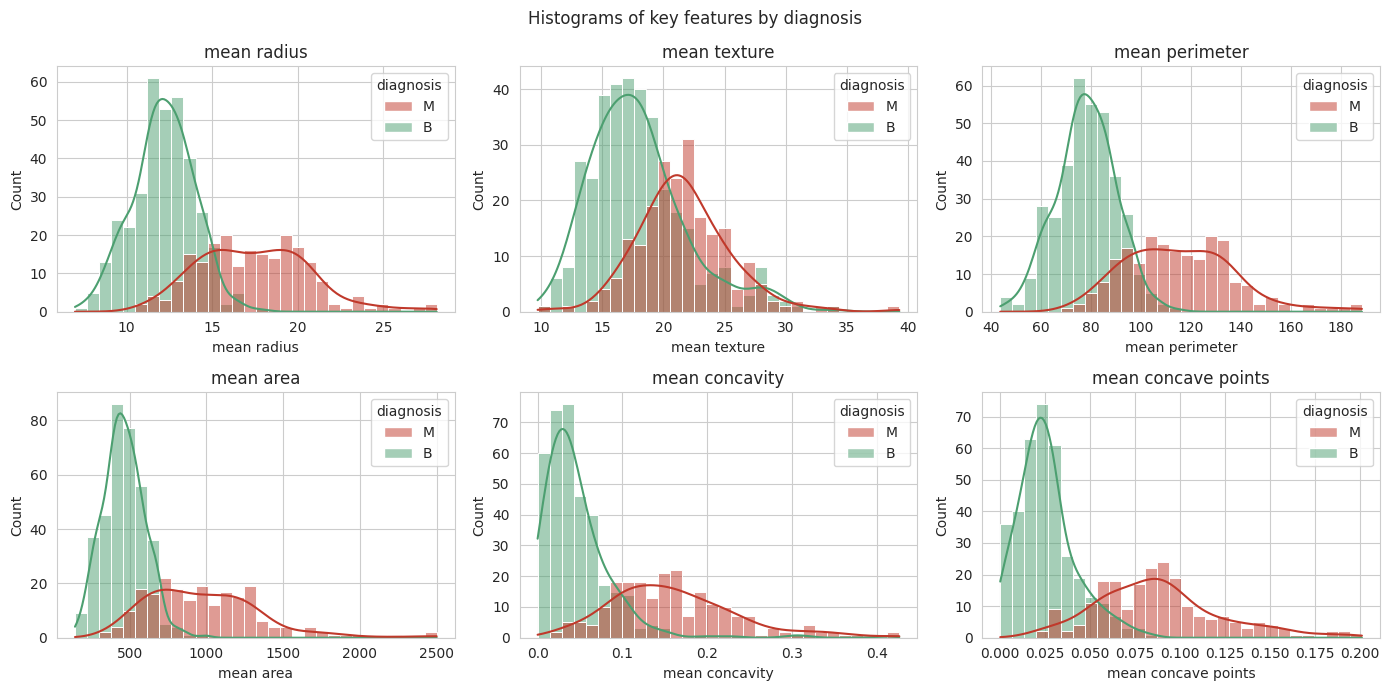

In [ ]:
key = ["mean radius", "mean texture", "mean perimeter", "mean area",
       "mean concavity", "mean concave points"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), key):
    sns.histplot(data=df, x=f, hue="diagnosis", bins=30, kde=True,
                 palette={"B": "#4c9f70", "M": "#c0392b"}, ax=ax)
    ax.set_title(f)
plt.suptitle("Histograms of key features by diagnosis")
plt.tight_layout(); plt.show()

**Box plots of key features by diagnosis**

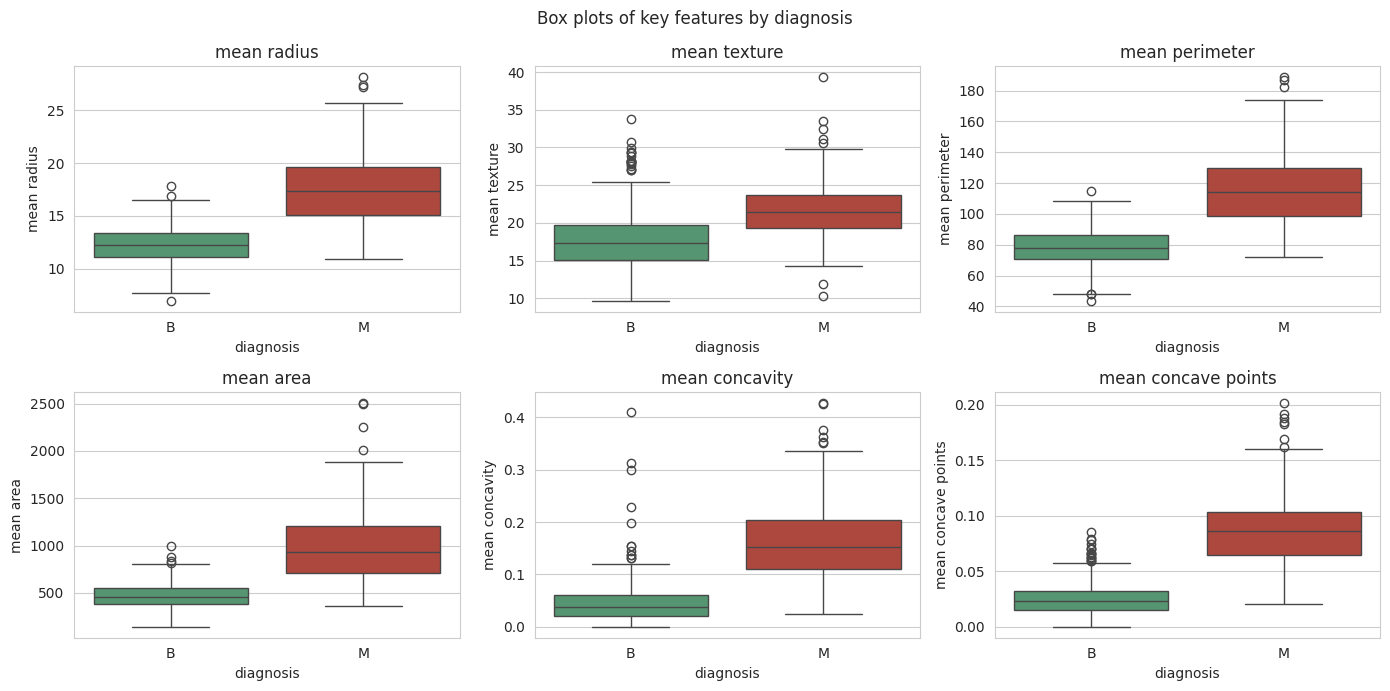

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), key):
    sns.boxplot(data=df, x="diagnosis", y=f, order=["B", "M"],
                palette=["#4c9f70", "#c0392b"], ax=ax)
    ax.set_title(f)
plt.suptitle("Box plots of key features by diagnosis")
plt.tight_layout(); plt.show()

**Correlation heatmap**

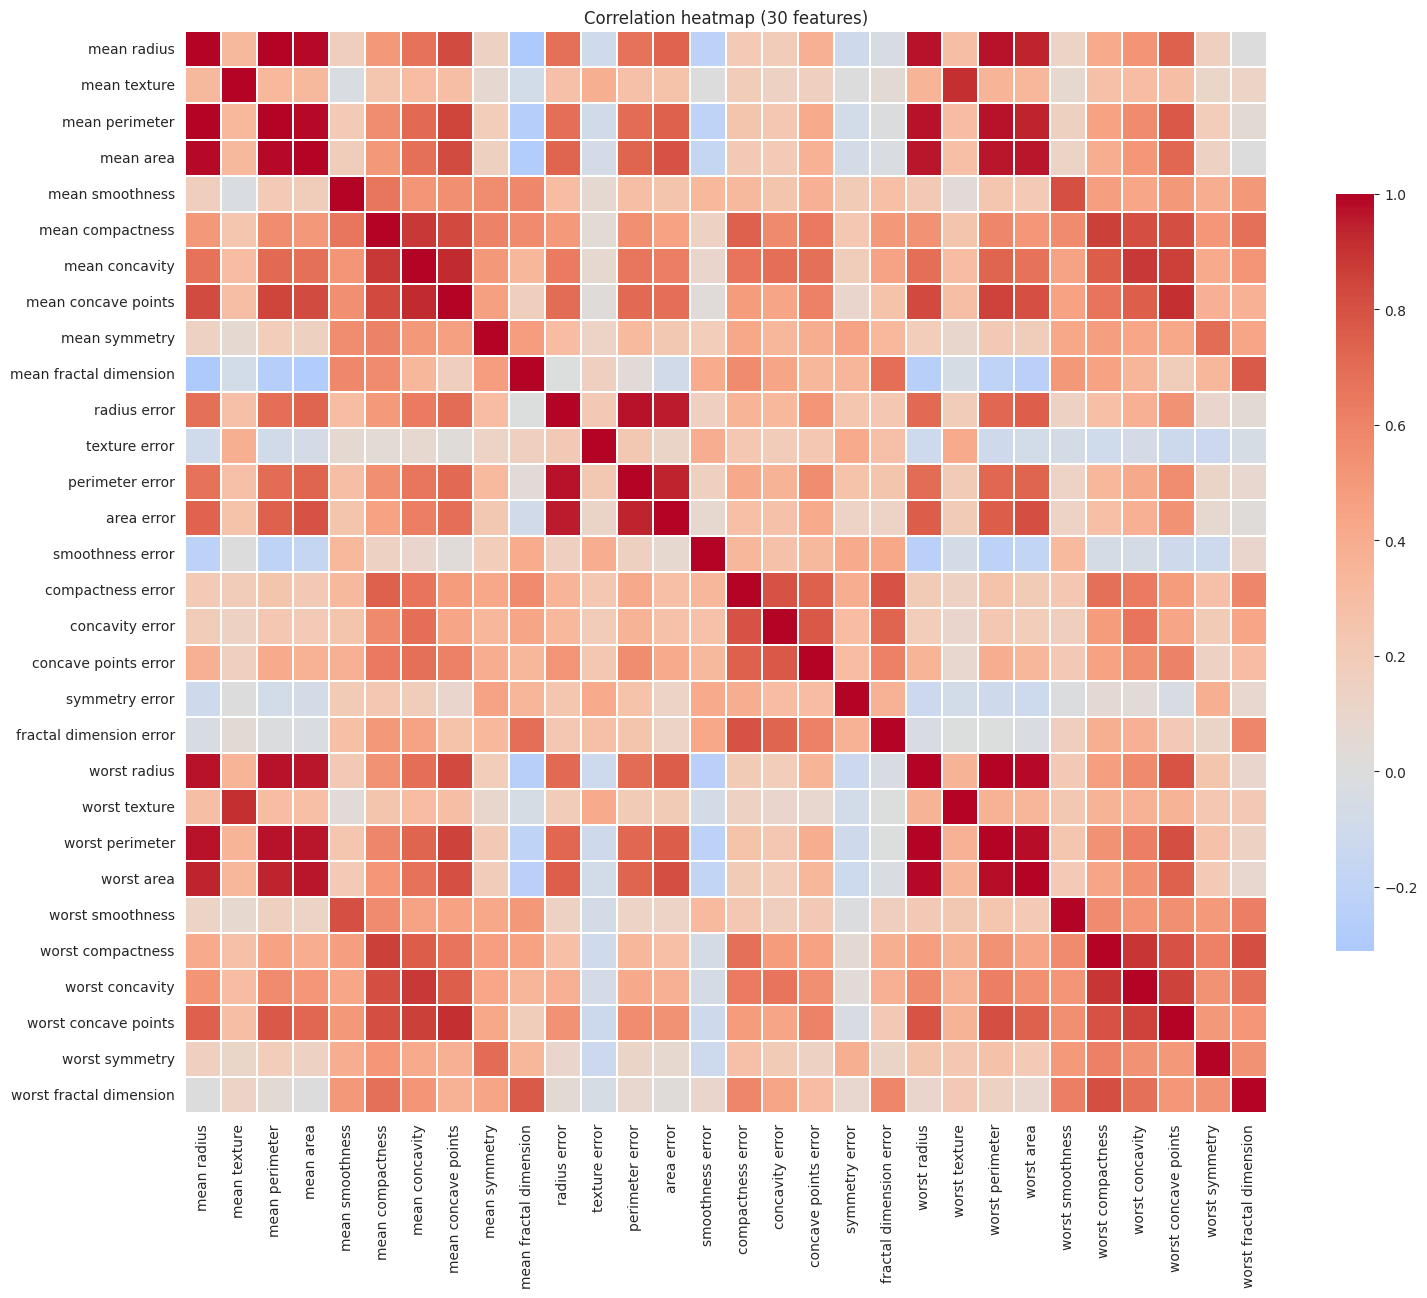

Top 5 correlated pairs:
 mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984
dtype: float64

Pairs with |r| > 0.9: 21


In [ ]:
corr = df[features].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.7}, linewidths=0.2)
plt.title("Correlation heatmap (30 features)")
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().sort_values(ascending=False)
print("Top 5 correlated pairs:\n", pairs.head(5).round(3))
print("\nPairs with |r| > 0.9:", int((pairs.abs() > 0.9).sum()))

**Observations:** Malignant tumours have clearly larger radius, perimeter, area, concavity and concave points than benign ones, with only partial overlap, so these features separate the classes well. Many features are strongly correlated (e.g. mean radius vs mean perimeter, r = 0.998), which means redundant information (multicollinearity) and makes individual coefficients harder to interpret.

## 5. Class imbalance

In [ ]:
n_b, n_m = counts["B"], counts["M"]
print(f"Benign: {n_b} ({n_b/len(df):.1%}) | Malignant: {n_m} ({n_m/len(df):.1%}) | ratio = {n_b/n_m:.2f}:1")

Benign: 357 (62.7%) | Malignant: 212 (37.3%) | ratio = 1.68:1


**Discussion:** The data are mildly imbalanced (about 63% benign vs 37% malignant). This is not severe, but it has implications:
- A model that always predicted "benign" would already reach ~63% accuracy, so **accuracy alone is misleading**.
- The minority (malignant) class is the clinically critical one, so we must track its **recall and precision** separately.
- We use a **stratified split** so train and test sets keep the same class ratio.
- If recall on the malignant class were poor, options include `class_weight="balanced"`, resampling (SMOTE), or tuning the decision threshold.

# Task 2: Data Preprocessing

In [ ]:
# Encode target: Malignant = 1 (positive class), Benign = 0
y = (df["diagnosis"] == "M").astype(int)
X = df[features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Malignant share -> train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

# Standardize: fit on the training set ONLY to avoid data leakage
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Feature means after scaling (train, first 3):", X_train_s.mean(axis=0)[:3].round(6))
print("Feature std after scaling  (train, first 3):", X_train_s.std(axis=0)[:3].round(6))

Train: (455, 30) | Test: (114, 30)
Malignant share -> train: 0.374 | test: 0.368
Feature means after scaling (train, first 3): [-0.  0.  0.]
Feature std after scaling  (train, first 3): [1. 1. 1.]


- **Encoding:** malignant = 1 is the positive (disease) class, so recall means "fraction of cancers caught".
- **Stratified 80/20 split** keeps the class ratio equal in both sets.
- **Standardization** puts all features on the same scale (e.g. area is in the hundreds while smoothness is about 0.1). Logistic regression with regularization is sensitive to scale. The scaler is fitted on the training data only, then applied to the test data.

# Task 3: Model Training and Evaluation

In [ ]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
print(f"Accuracy: {acc:.4f}")
print(f"ROC AUC : {auc:.4f}\n")
print(classification_report(y_test, y_pred,
      target_names=["Benign (0)", "Malignant (1)"], digits=4))

Accuracy: 0.9649
ROC AUC : 0.9960

               precision    recall  f1-score   support

   Benign (0)     0.9595    0.9861    0.9726        72
Malignant (1)     0.9750    0.9286    0.9512        42

     accuracy                         0.9649       114
    macro avg     0.9672    0.9573    0.9619       114
 weighted avg     0.9652    0.9649    0.9647       114



**Confusion matrix**

TN=71  FP=1  FN=3  TP=39
Sensitivity (malignant recall) = 0.9286 | Specificity = 0.9861


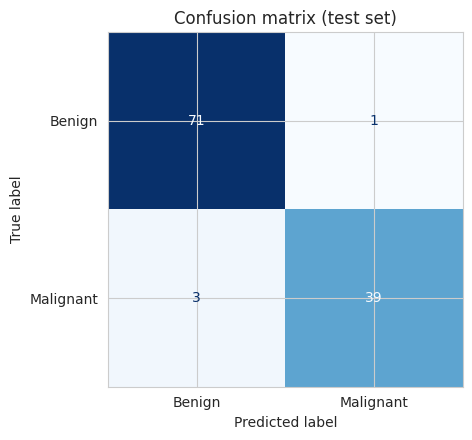

In [ ]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Sensitivity (malignant recall) = {tp/(tp+fn):.4f} | Specificity = {tn/(tn+fp):.4f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()

**ROC curve and AUC**

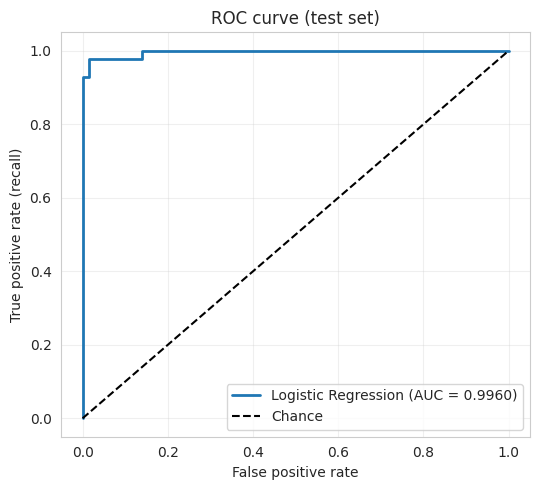

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, lw=2, label=f"Logistic Regression (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curve (test set)"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Most influential features (standardized coefficients)**

In [ ]:
coef = pd.Series(model.coef_[0], index=features).sort_values(key=np.abs, ascending=False)
coef.head(8).round(3)

,0
worst texture,1.434
radius error,1.233
worst symmetry,1.061
mean concave points,0.953
worst concavity,0.911
area error,0.909
compactness error,-0.907
worst area,0.900


## Interpretation of results

| Metric | Benign | Malignant |
|---|---|---|
| Precision | 0.960 | 0.975 |
| Recall | 0.986 | 0.929 |
| F1-score | 0.973 | 0.951 |

Overall accuracy is **96.5%** and ROC AUC is **0.996**.

